# 05 Altitude, lake size and a real train/test split

This notebook extends the analysis in three ways:
1. **M4** adds lake altitude to M3. Altitude is known for all 64 sites.
2. **M5** adds lake area and mean depth on top of M4. These are only reliable for 53 sites, so M5 is
   compared with M4 refitted on the same 53 sites.
3. **A held-out test set.** 12 lakes (5 south, 5 central, 2 north, drawn at random) are removed
   completely, and all seasons after 2010 are kept out of training. The models are fitted on the
   remaining 52 lakes up to 2010 and then predict three test sets:
   - **A**: the training lakes in 2011-2026 (known lakes, unseen years)
   - **B**: the held-out lakes up to 2010 (unseen lakes, known years)
   - **C**: the held-out lakes in 2011-2026 (unseen lakes and unseen years, which is what the lake
     predictor app does)

Run `python run_extended.py` first (about 1.5-2 hours). It saves every fit to `results/` and writes
the test-set scores to `results/split_metrics.csv`. This notebook only loads and reports them.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az

import icebreak_common as ic

warnings.filterwarnings("ignore", message="libc not found")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REGION_COLORS = {"south": "#2a6fbb", "central": "#3a9e6f", "north": "#c4572a"}

d = ic.load_breakup(recent_only=True)
R = ic.RES_DIR
def load(name):
    p = R / f"{name}.nc"
    return az.from_netcdf(p) if p.exists() else None

fits = {n: load(n) for n in ["M1_hier_linear", "M2_hier_broken", "M3_hier_broken_region",
                             "M4_altitude", "M4_altitude_prior0.5", "M4_altitude_prior2.0",
                             "M4_altitude_reliable", "M5_lake_size"]}
print({k: (v is not None) for k, v in fits.items()})

{'M1_hier_linear': True, 'M2_hier_broken': True, 'M3_hier_broken_region': True, 'M4_altitude': True, 'M4_altitude_prior0.5': True, 'M4_altitude_prior2.0': True, 'M4_altitude_reliable': True, 'M5_lake_size': True}


## 1. Convergence of the new fits
Targets as before: R-hat < 1.01, bulk and tail ESS > 400, no divergences. M1 and M2 are the refitted
versions with 2000 warm-up and 2000 sampling iterations per chain.

In [2]:
diag = {n: ic.diagnostics_table(v) for n, v in fits.items() if v is not None}
for p in sorted((R / "split").glob("*.nc")):
    diag["split/" + p.stem] = ic.diagnostics_table(az.from_netcdf(p))
diag_tab = pd.DataFrame(diag).T
diag_tab["ok"] = ((diag_tab["max R-hat"] < 1.01) & (diag_tab["min bulk-ESS"] > 400)
                  & (diag_tab["min tail-ESS"] > 400) & (diag_tab["divergences"] == 0))
diag_tab.round(3)

,max R-hat,min bulk-ESS,min tail-ESS,divergences,parameters,ok
M1_hier_linear,1.01,233.0,332.0,0.0,520.0,False
M2_hier_broken,1.01,369.0,636.0,0.0,521.0,False
M3_hier_broken_region,1.00,1147.0,1841.0,0.0,1232.0,True
M4_altitude,1.01,1438.0,2038.0,0.0,1233.0,False
M4_altitude_prior0.5,1.01,1644.0,1821.0,0.0,1233.0,False
M4_altitude_prior2.0,1.00,1600.0,2201.0,0.0,1233.0,True
M4_altitude_reliable,1.01,1820.0,1862.0,0.0,1189.0,False
M5_lake_size,1.01,1533.0,2060.0,0.0,1191.0,False
split/M0_pooled,1.00,2634.0,2573.0,0.0,6.0,True
split/M1_hier_linear,1.01,269.0,513.0,0.0,440.0,False


## 2. What altitude adds (M4)
The altitude prior is $N(0, 5)$ days per 100 m. Air temperature drops by roughly 0.6 °C per 100 m, so an
effect of a few days per 100 m is plausible, and the prior allows much more in both directions.

In [3]:
key = ["Intercept", "lat_c", "lon_c", "alt_c", "decade_c", "post1980", "lat_c:decade_c",
       "1|site_sigma", "decade_c|site_sigma", "1|season_f_sigma", "1|season_region_sigma",
       "sigma", "nu"]

def summ_table(names):
    out = {}
    for n in names:
        if fits.get(n) is None:
            continue
        post = fits[n].posterior
        vs = [v for v in key + ["logarea_c", "depth_c"] if v in post]
        s = az.summary(fits[n], var_names=vs, hdi_prob=0.9, kind="stats")
        out[n] = s["mean"].round(2).astype(str) + " [" + s["hdi_5%"].round(2).astype(str) \
            + ", " + s["hdi_95%"].round(2).astype(str) + "]"
    return pd.DataFrame(out).reindex(key + ["logarea_c", "depth_c"]).fillna("-")

tab_m4 = summ_table(["M3_hier_broken_region", "M4_altitude"])
tab_m4.to_csv(R / "posterior_summary_M4.csv")
tab_m4

,M3_hier_broken_region,M4_altitude
Intercept,"131.58 [129.27, 133.97]","131.0 [128.65, 133.4]"
lat_c,"4.51 [4.2, 4.8]","3.71 [3.42, 4.04]"
lon_c,"0.05 [-0.25, 0.37]","0.42 [0.18, 0.69]"
alt_c,-,"3.74 [2.89, 4.63]"
decade_c,"-0.41 [-0.9, 0.02]","-0.41 [-0.86, 0.04]"
post1980,"-2.26 [-3.4, -1.05]","-2.25 [-3.42, -1.08]"
lat_c:decade_c,"0.1 [0.05, 0.14]","0.1 [0.06, 0.15]"
1|site_sigma,"3.14 [2.67, 3.64]","2.3 [1.95, 2.65]"
decade_c|site_sigma,"0.24 [0.19, 0.29]","0.24 [0.19, 0.28]"
1|season_f_sigma,"6.45 [5.69, 7.22]","6.45 [5.7, 7.28]"


In [4]:
P4 = {v: ic.draws(fits["M4_altitude"].posterior, v) for v in key}
P3 = {v: ic.draws(fits["M3_hier_broken_region"].posterior, v) for v in key if v != "alt_c"}
def ci(x, s=1.0):
    x = np.asarray(x) * s
    return f"{x.mean():.2f} [{np.percentile(x, 5):.2f}, {np.percentile(x, 95):.2f}]"
alt_res = pd.Series({
    "Altitude effect, days per 100 m (90% CI)": ci(P4["alt_c"]),
    "P(altitude effect > 0)": f"{np.mean(P4['alt_c'] > 0):.3f}",
    "Latitude effect in M3, days per degree": ci(P3["lat_c"]),
    "Latitude effect in M4, days per degree": ci(P4["lat_c"]),
    "Lake-level SD in M3 (days)": ci(P3["1|site_sigma"]),
    "Lake-level SD in M4 (days)": ci(P4["1|site_sigma"]),
    "Trend after 1980 in M4, days/decade": ci(P4["decade_c"] + P4["post1980"]),
    "Change 1980 to 2026 in M4, days": ci((P4["decade_c"] + P4["post1980"]) * 4.6),
})
alt_res.to_csv(R / "key_numbers_M4.csv")
alt_res

Altitude effect, days per 100 m (90% CI)         3.74 [2.84, 4.58]
P(altitude effect > 0)                                       1.000
Latitude effect in M3, days per degree           4.51 [4.20, 4.80]
Latitude effect in M4, days per degree           3.71 [3.40, 4.03]
Lake-level SD in M3 (days)                       3.14 [2.69, 3.68]
Lake-level SD in M4 (days)                       2.30 [1.97, 2.68]
Trend after 1980 in M4, days/decade           -2.67 [-3.53, -1.77]
Change 1980 to 2026 in M4, days             -12.27 [-16.26, -8.15]
dtype: object

If altitude explains part of the differences between lakes, the lake-level SD drops from M3 to M4. Because
altitude and latitude are correlated ($r = 0.65$), the latitude effect may also shrink a little: part of
what M3 attributed to latitude is really height above sea level.

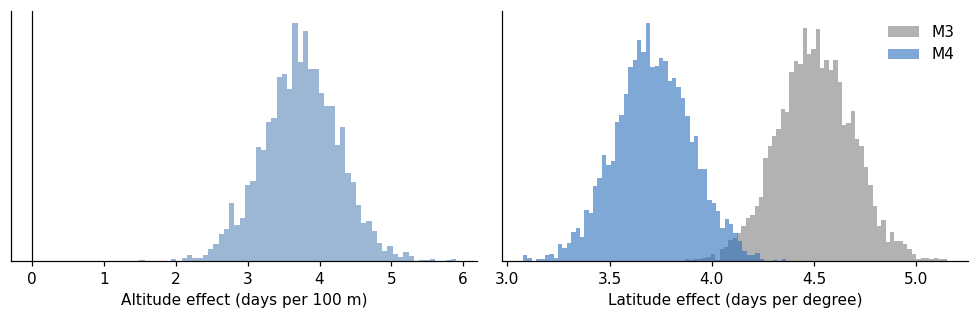

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(P4["alt_c"], bins=60, color="#9bb7d4", density=True)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("Altitude effect (days per 100 m)")
axes[0].set_yticks([])
for P, lab, col in [(P3, "M3", "grey"), (P4, "M4", "#2a6fbb")]:
    axes[1].hist(P["lat_c"], bins=60, density=True, alpha=0.6, color=col, label=lab)
axes[1].set_xlabel("Latitude effect (days per degree)")
axes[1].set_yticks([])
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig16_altitude.png", bbox_inches="tight")
plt.show()

## 3. Does altitude improve prediction? PSIS-LOO, M3 against M4

In [6]:
cmp = az.compare({"M3 (no altitude)": fits["M3_hier_broken_region"], "M4 (altitude)": fits["M4_altitude"]},
                 ic="loo")
cmp.to_csv(R / "loo_compare_M3_M4.csv")
cmp

/Users/marino/miniconda3/envs/collegeEnv/lib/python3.10/site-packages/arviz/stats/stats.py:782: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
M4 (altitude),0,-15390.626747,581.501749,0.000000,1.0,80.387694,0.000000,True,log
M3 (no altitude),1,-15392.799343,583.879323,2.172596,0.0,80.346308,1.282878,False,log


Altitude is a lake-level covariate, so most of its information is already captured by the lake-level
intercepts when a lake has many years of data. A small LOO difference is therefore expected even if the
effect is real. Where altitude matters most is for lakes the model has never seen, which section 6 tests.

## 4. Posterior predictive check for M4
The same checks as for M0-M3 in notebook 03: density overlay and the regional correlation of yearly
anomalies (observed south-north correlation 0.54).

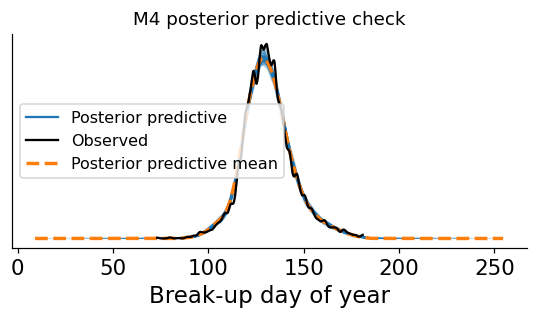

,observed,replicated mean,p-value
south-central,0.903,0.908,0.792
south-north,0.540,0.577,0.934
central-north,0.685,0.687,0.567


In [7]:
m4 = ic.build_model("M4_altitude", d)
m4.build()
thin = fits["M4_altitude"].sel(draw=slice(None, None, 4))
pp = ic.predict(m4, thin, "response", inplace=False)
fig, ax = plt.subplots(figsize=(5, 3))
az.plot_ppc(pp, num_pp_samples=100, ax=ax)
ax.set_xlabel("Break-up day of year")
ax.set_title("M4 posterior predictive check")
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig17_ppc_M4.png", bbox_inches="tight")
plt.show()

yrep = pp.posterior_predictive[ic.RESPONSE].stack(sample=("chain", "draw")).transpose("sample", ...).values
y = d[ic.RESPONSE].to_numpy()

def region_corr(Y):
    Y = np.atleast_2d(Y)
    cells = d.groupby(["season", "region"]).indices
    seasons = sorted(d.season.unique())
    out = []
    for a, b in [("south", "central"), ("south", "north"), ("central", "north")]:
        both = [s for s in seasons if (s, a) in cells and (s, b) in cells]
        xa = np.stack([Y[:, cells[(s, a)]].mean(1) for s in both], 1)
        xb = np.stack([Y[:, cells[(s, b)]].mean(1) for s in both], 1)
        xa -= xa.mean(1, keepdims=True)
        xb -= xb.mean(1, keepdims=True)
        out.append((xa * xb).sum(1) / np.sqrt((xa ** 2).sum(1) * (xb ** 2).sum(1)))
    return np.stack(out, 1)

obs_c = region_corr(y)[0]
rep_c = region_corr(yrep)
pd.DataFrame({"observed": obs_c, "replicated mean": rep_c.mean(0),
              "p-value": (rep_c >= obs_c).mean(0)},
             index=["south-central", "south-north", "central-north"]).round(3)

## 5. Prior sensitivity for M4

In [8]:
rows = []
for sc, n in [(0.5, "M4_altitude_prior0.5"), (1.0, "M4_altitude"), (2.0, "M4_altitude_prior2.0")]:
    if fits.get(n) is None:
        continue
    post = fits[n].posterior
    for v in ["lat_c", "lon_c", "alt_c", "decade_c", "post1980", "decade_c|site_sigma"]:
        x = ic.draws(post, v)
        rows.append({"parameter": v, "prior scale": sc, "mean": x.mean(),
                     "q5": np.percentile(x, 5), "q95": np.percentile(x, 95)})
sens = pd.DataFrame(rows)
sens.pivot_table(index="parameter", columns="prior scale", values="mean").round(2)

prior scale,0.5,1.0,2.0
parameter,,,
alt_c,3.65,3.74,3.76
decade_c,-0.48,-0.41,-0.39
decade_c|site_sigma,0.24,0.24,0.24
lat_c,3.71,3.71,3.71
lon_c,0.41,0.42,0.42
post1980,-1.99,-2.25,-2.35


## 6. Lake size and depth (M5), on the 53 sites with reliable lake data
Area enters as log area (per 2.7-fold change) and depth per 5 m of mean depth. M4 is refitted on exactly the
same 53 sites so the LOO comparison is fair.

In [9]:
if fits.get("M5_lake_size") is not None:
    P5 = {v: ic.draws(fits["M5_lake_size"].posterior, v) for v in ["alt_c", "logarea_c", "depth_c", "lat_c"]}
    display(pd.Series({
        "Lake area, days per 2.7x larger area": ci(P5["logarea_c"]),
        "Lake area, days per 10x larger area": ci(P5["logarea_c"], np.log(10)),
        "P(larger lakes break up later)": f"{np.mean(P5['logarea_c'] > 0):.3f}",
        "Mean depth, days per 5 m deeper": ci(P5["depth_c"]),
        "P(deeper lakes break up later)": f"{np.mean(P5['depth_c'] > 0):.3f}",
        "Altitude in M5, days per 100 m": ci(P5["alt_c"]),
    }))
    cmp5 = az.compare({"M4 (53 sites)": fits["M4_altitude_reliable"],
                       "M5 (+ area, depth)": fits["M5_lake_size"]}, ic="loo")
    cmp5.to_csv(R / "loo_compare_M4_M5.csv")
    display(cmp5)

Lake area, days per 2.7x larger area    -0.09 [-0.56, 0.38]
Lake area, days per 10x larger area     -0.21 [-1.28, 0.87]
P(larger lakes break up later)                        0.370
Mean depth, days per 5 m deeper           1.65 [0.71, 2.58]
P(deeper lakes break up later)                        0.998
Altitude in M5, days per 100 m            3.31 [2.25, 4.37]
dtype: object

,rank,elpd_loo,p_loo,elpd_diff,weight,se,dse,warning,scale
M4 (53 sites),0,-12759.170203,549.408680,0.000000,1.000000e+00,74.384283,0.000000,False,log
"M5 (+ area, depth)",1,-12761.241037,550.634456,2.070833,5.551115e-17,74.320082,0.984883,False,log


## 7. Held-out test set
Every model was fitted on 52 lakes up to 2010 and then asked to predict data it never saw. For unseen
lakes the model draws a new lake effect from the fitted between-lake distribution, and for unseen years a
new year effect, so the intervals include that uncertainty.

Scores:
- **elpd**: log predictive density of the test data (higher is better), with its SE
- **MAE**: mean absolute error of the predictive median, in days
- **cover90 / cover50**: share of test dates inside the 90% / 50% predictive interval (should be close to 0.9 / 0.5)
- **width90**: average width of the 90% interval, in days

Two non-Bayesian baselines give context: the lake's own training mean (test set A) and a straight line of
site mean against latitude (test sets B and C).

In [10]:
sm = pd.read_csv(R / "split_metrics.csv")
show = sm.copy()
for c in ["elpd", "elpd_se", "MAE_days", "RMSE_days", "width90_days"]:
    show[c] = show[c].round(1)
for c in ["elpd_per_obs", "cover50", "cover90"]:
    show[c] = show[c].round(2)
show = show.set_index(["test_set", "model"]).sort_index()
show.to_csv(R / "split_metrics_table.csv")
show

n    elpd  elpd_se  elpd_per_obs  \
test_set model                                                                 
A_future M0_pooled                        687 -2737.3     37.3         -3.98   
         M1_hier_linear                   687 -2654.4     33.8         -3.86   
         M2_hier_broken                   687 -2514.0     26.4         -3.66   
         M3_hier_broken_region            687 -2516.3     23.9         -3.66   
         M4_altitude                      687 -2498.9     21.8         -3.64   
         baseline: lake's training mean   687     NaN      NaN           NaN   
B_lakes  M0_pooled                       1079 -3764.1     22.9         -3.49   
         M1_hier_linear                  1079 -3061.7     24.2         -2.84   
         M2_hier_broken                  1079 -3066.8     23.5         -2.84   
         M3_hier_broken_region           1079 -2951.4     22.3         -2.74   
         M4_altitude                     1079 -3047.9     37.8         -2.82   
         baseline: latitude line         1079     NaN      NaN           NaN   
C_both   M0_pooled                        156  -636.0     19.1         -4.08   
         M1_hier_linear                   156  -627.1     16.9         -4.02   
         M2_hier_broken                   156  -574.7     10.6         -3.68   
         M3_hier_broken_region            156  -582.6     12.7         -3.73   
         M4_altitude                      156  -582.2     12.2         -3.73   
         baseline: latitude line          156     NaN      NaN           NaN   

                                         MAE_days  RMSE_days  cover50  \
test_set model                                                          
A_future M0_pooled                            8.8       11.4     0.40   
         M1_hier_linear                       8.0       10.6     0.47   
         M2_hier_broken                       7.1        9.3     0.50   
         M3_hier_broken_region                7.2        9.4     0.50   
         M4_altitude                          7.1        9.2     0.54   
         baseline: lake's training mean      10.7       13.4      NaN   
B_lakes  M0_pooled                            6.4        7.9     0.49   
         M1_hier_linear                       3.1        4.3     0.59   
         M2_hier_broken                       3.1        4.3     0.60   
         M3_hier_broken_region                2.8        3.8     0.64   
         M4_altitude                          3.1        4.5     0.55   
         baseline: latitude line              6.7        8.3      NaN   
C_both   M0_pooled                            9.3       12.0     0.39   
         M1_hier_linear                       9.0       11.8     0.40   
         M2_hier_broken                       7.5        9.7     0.47   
         M3_hier_broken_region                7.7       10.0     0.50   
         M4_altitude                          7.8        9.9     0.44   
         baseline: latitude line             11.9       14.6      NaN   

                                         cover90  width90_days  
test_set model                                                  
A_future M0_pooled                          0.76          26.4  
         M1_hier_linear                     0.79          26.6  
         M2_hier_broken                     0.83          26.2  
         M3_hier_broken_region              0.85          27.8  
         M4_altitude                        0.88          29.4  
         baseline: lake's training mean      NaN           NaN  
B_lakes  M0_pooled                          0.91          26.4  
         M1_hier_linear                     0.94          16.6  
         M2_hier_broken                     0.95          17.8  
         M3_hier_broken_region              0.95          15.5  
         M4_altitude                        0.86          12.1  
         baseline: latitude line             NaN           NaN  
C_both   M0_pooled                          0.74          26.3  
       

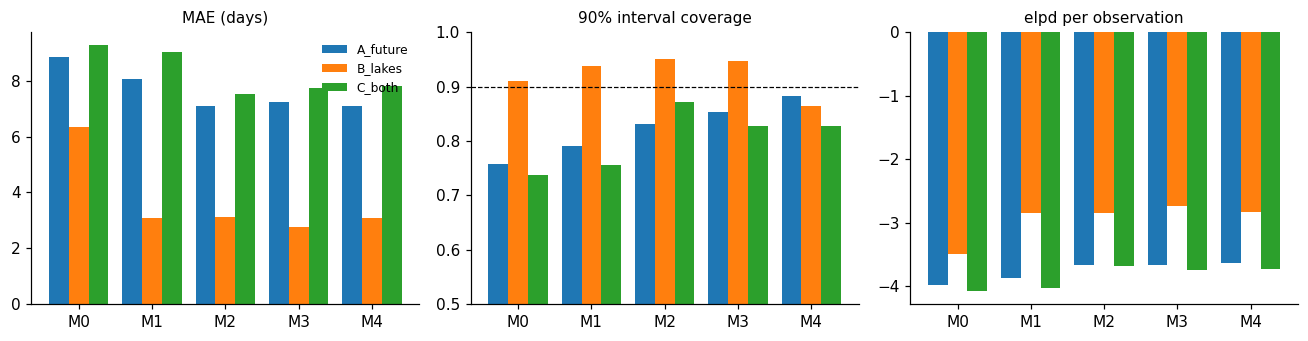

In [11]:
models_order = ["M0_pooled", "M1_hier_linear", "M2_hier_broken", "M3_hier_broken_region", "M4_altitude"]
labels = ["M0", "M1", "M2", "M3", "M4"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, metric, lab in zip(axes, ["MAE_days", "cover90", "elpd_per_obs"],
                           ["MAE (days)", "90% interval coverage", "elpd per observation"]):
    for k, t in enumerate(["A_future", "B_lakes", "C_both"]):
        sub = sm[(sm.test_set == t) & sm.model.isin(models_order)].set_index("model").reindex(models_order)
        ax.bar(np.arange(5) + (k - 1) * 0.27, sub[metric], width=0.27, label=t)
    ax.set_xticks(range(5), labels)
    ax.set_title(lab, fontsize=10)
    if metric == "cover90":
        ax.axhline(0.9, color="k", lw=0.8, ls="--")
        ax.set_ylim(0.5, 1)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig18_test_scores.png", bbox_inches="tight")
plt.show()

Predictions for the hardest test set (C: unseen lakes in unseen years) from M4, one panel per held-out lake.

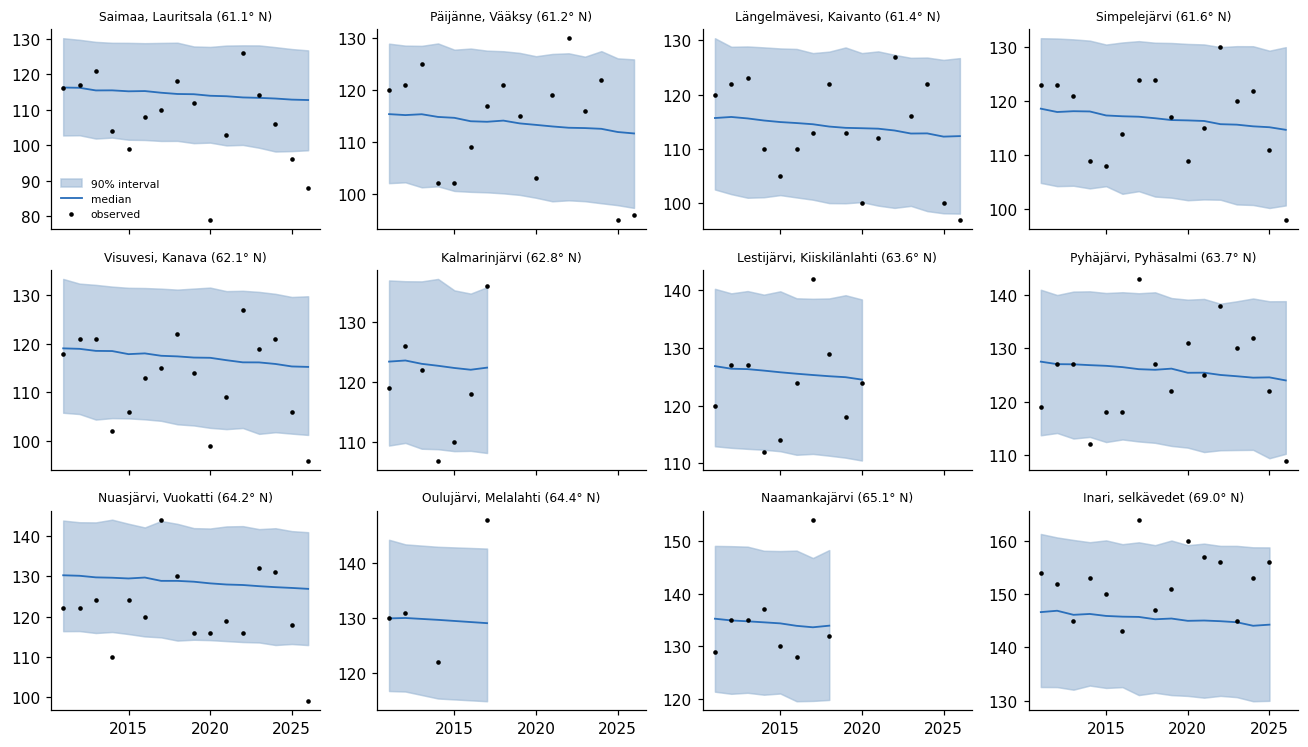

In [12]:
pr = pd.read_csv(R / "split_predictions.csv")
c4 = pr[(pr.model == "M4_altitude") & (pr.test_set == "C_both")]
lakes = c4.groupby("site").lat.first().sort_values().index
n = len(lakes)
fig, axes = plt.subplots(int(np.ceil(n / 4)), 4, figsize=(12, 2.3 * np.ceil(n / 4)), sharex=True)
for ax, s in zip(axes.ravel(), lakes):
    g = c4[c4.site == s].sort_values("season")
    ax.fill_between(g.season, g.q5, g.q95, color="#9bb7d4", alpha=0.6, label="90% interval")
    ax.plot(g.season, g["median"], color="#2a6fbb", lw=1.2, label="median")
    ax.plot(g.season, g.y, "k.", ms=4, label="observed")
    ax.set_title(f"{g.name.iloc[0]} ({g.lat.iloc[0]:.1f}° N)", fontsize=8)
for ax in axes.ravel()[n:]:
    ax.axis("off")
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(ic.FIG_DIR / "fig19_test_C_lakes.png", bbox_inches="tight")
plt.show()

**Reading the results.** Coverage close to 0.9 means the uncertainty is honest. MAE shows how far off a
single best guess is; for unseen years most of the error comes from the weather of that year, which no
model without weather data can know in advance. Compare the models within each test set, not across sets.

## 8. Numbers for the report

In [13]:
pd.concat([alt_res]).to_frame("value")

,value
"Altitude effect, days per 100 m (90% CI)","3.74 [2.84, 4.58]"
P(altitude effect > 0),1.000
"Latitude effect in M3, days per degree","4.51 [4.20, 4.80]"
"Latitude effect in M4, days per degree","3.71 [3.40, 4.03]"
Lake-level SD in M3 (days),"3.14 [2.69, 3.68]"
Lake-level SD in M4 (days),"2.30 [1.97, 2.68]"
"Trend after 1980 in M4, days/decade","-2.67 [-3.53, -1.77]"
"Change 1980 to 2026 in M4, days","-12.27 [-16.26, -8.15]"
